# Codeabgabe für Data Visualization

### Airline Analysis

This analysis was created as a university project to predict future customer relationship and explain concrete painpoints to improve

1. [Data Cleaning](#data_cleaning)
2. [Data Exploration](#data_exploration)
3. [Predictive Modelling](#predictive_modelling)

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("airline.csv", delimiter="|")


### Allgemeine Zufriedenheit der Kunden checken

Text(0, 0.5, 'Anzahl der Kunden')

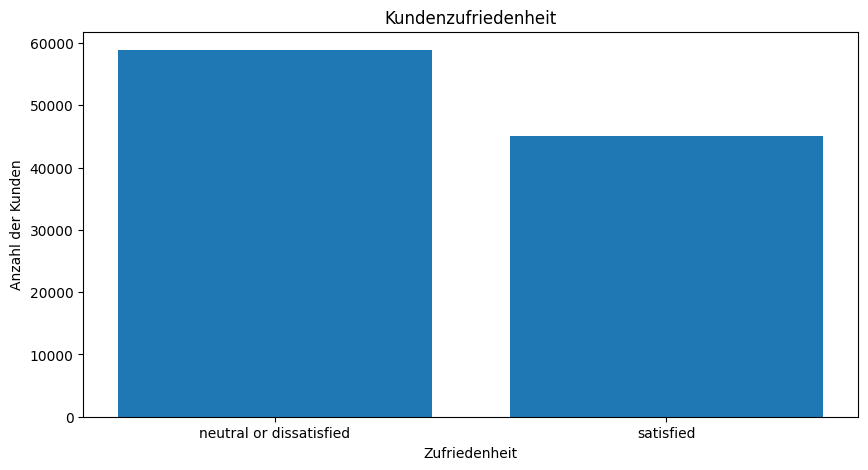

In [3]:
fig, ax = plt.subplots(figsize=(10,5))

ax.bar(df['satisfaction'].unique(), df['satisfaction'].value_counts())

ax.set_title('Kundenzufriedenheit')
ax.set_xlabel('Zufriedenheit')
ax.set_ylabel('Anzahl der Kunden')


### with df.info() number of rows and columns

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 103907 entries, 0 to 103906
Data columns (total 13 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   Gender                      103907 non-null  str    
 1   Customer Type               103907 non-null  str    
 2   Age                         103904 non-null  float64
 3   Type of Travel              103907 non-null  str    
 4   Class                       103907 non-null  str    
 5   Flight Distance             103907 non-null  int64  
 6   Food and drink              103907 non-null  int64  
 7   On-board service            103907 non-null  int64  
 8   Leg room service            103907 non-null  str    
 9   Departure Delay in Minutes  103907 non-null  int64  
 10  satisfaction                103907 non-null  str    
 11  Customer ID                 103907 non-null  int64  
 12  isPilot                     103907 non-null  bool   
dtypes: bool(1), float64(1), i

### Columns dont have snake_case

In [5]:
df.columns = df.columns.str.replace(' ', '_')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 103907 entries, 0 to 103906
Data columns (total 13 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   Gender                      103907 non-null  str    
 1   Customer_Type               103907 non-null  str    
 2   Age                         103904 non-null  float64
 3   Type_of_Travel              103907 non-null  str    
 4   Class                       103907 non-null  str    
 5   Flight_Distance             103907 non-null  int64  
 6   Food_and_drink              103907 non-null  int64  
 7   On-board_service            103907 non-null  int64  
 8   Leg_room_service            103907 non-null  str    
 9   Departure_Delay_in_Minutes  103907 non-null  int64  
 10  satisfaction                103907 non-null  str    
 11  Customer_ID                 103907 non-null  int64  
 12  isPilot                     103907 non-null  bool   
dtypes: bool(1), float64(1), i

### Age is not complete for Non-Null Count & Leg room service should be an integer

### Testing numerical columns

In [6]:
df.describe()

,Age,Flight_Distance,Food_and_drink,On-board_service,Departure_Delay_in_Minutes,Customer_ID
count,103904.000000,103907.000000,103907.000000,103907.00000,103907.000000,103907.000000
mean,39.381054,1189.437593,3.202123,3.38238,14.815191,51953.000000
std,15.121206,997.161287,1.329521,1.28834,38.230432,29995.511548
min,-24.000000,-200.000000,0.000000,0.00000,0.000000,0.000000
25%,27.000000,414.000000,2.000000,2.00000,0.000000,25976.500000
50%,40.000000,843.000000,3.000000,4.00000,0.000000,51953.000000
75%,51.000000,1743.000000,4.000000,4.00000,12.000000,77929.500000
max,129.000000,4983.000000,5.000000,5.00000,1592.000000,103906.000000


### lowest & highest age of -24 & 129, shortest flight distance -200, 1592 minutes maximum delay 

>### 1. Data Cleaning <a name="data_cleaning">

### Visualisation of outliers

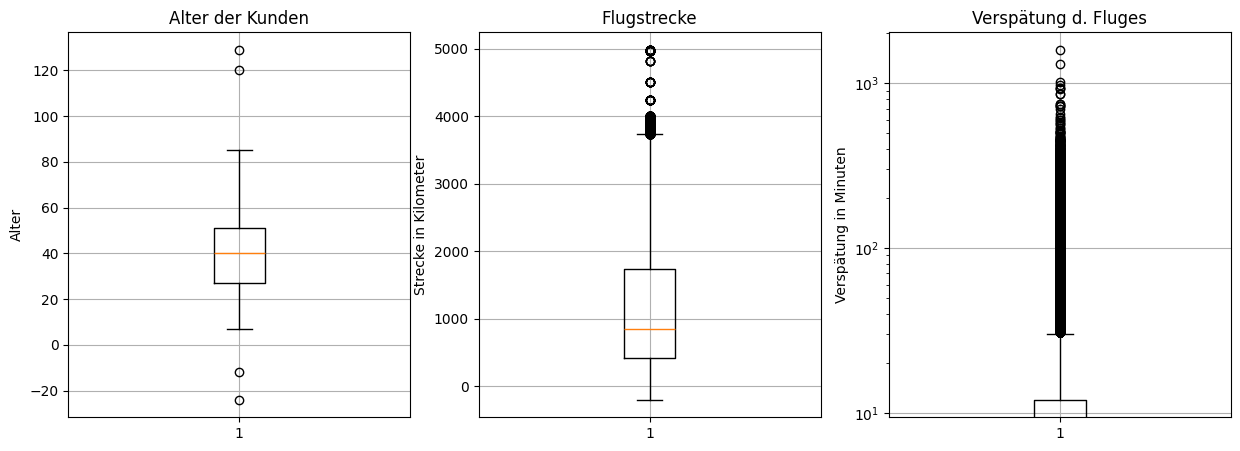

In [7]:
fig, ax = plt.subplots(1,3, figsize = (15,5))

ax[0].set_title("Alter der Kunden")
ax[0].set_ylabel("Alter")
ax[0].boxplot(df['Age'].dropna())
ax[0].grid()

ax[1].set_title("Flugstrecke")
ax[1].set_ylabel("Strecke in Kilometer")
ax[1].boxplot(df['Flight_Distance'])
ax[1].grid()

ax[2].set_title("Verspätung d. Fluges")
ax[2].set_ylabel("Verspätung in Minuten")
ax[2].set_yscale("log")
ax[2].boxplot(df['Departure_Delay_in_Minutes'])
ax[2].grid()

### checking for duplicates

In [8]:
print (df.duplicated().sum())

0


### filling empty age entries using median

In [9]:
age_median = df['Age'].median()
for i in range(len(df)):
    if df['Age'].isna()[i]:
        df.loc[i, 'Age'] = age_median


### Fixing numeric outliers

#### Fixing age outliers

In [10]:
for i in range(len(df)):
    if df.loc[i, 'Age'] < 0 or df.loc[i, 'Age'] > 100 : 
        df.loc[i, 'Age'] = age_median

#### Fixing negative flight distance outlier

In [11]:
flight_distance_median = df['Flight_Distance'].median()
for i in range(len(df)):
    if df.loc[i, 'Flight_Distance'] < 0 :
        df.loc[i, 'Flight_Distance'] = flight_distance_median

### Standardizing

In [12]:
for col in df.columns:
    print(col, df[col].unique())

Gender <StringArray>
['Male', 'Female']
Length: 2, dtype: str
Customer_Type <StringArray>
['Loyal Customer', 'disloyal Customer']
Length: 2, dtype: str
Age [13. 25. 26. 61. 47. 52. 41. 20. 24. 12. 53. 33. 45. 38.  9. 17. 43. 58.
 23. 57. 49. 36. 22. 31. 15. 35. 67. 37. 40. 34. 39. 50. 29. 54. 21. 28.
 27. 69. 60. 48. 59. 46. 30. 66. 64. 44. 51. 32. 19. 42. 16. 11. 62.  8.
 56. 68. 55. 18. 65. 72. 70. 63. 10.  7. 14. 80. 74. 71. 85. 73. 76. 77.
 75. 79. 78.]
Type_of_Travel <StringArray>
['Personal Travel', 'Business travel', 'Privat', 'Personal', 'Business']
Length: 5, dtype: str
Class <StringArray>
[       'Eco Plus',        'Business',             'Eco',            'Eco+',
         'Economy',           'Eco +',  'Business Class', 'Business Klasse']
Length: 8, dtype: str
Flight_Distance [ 460  235 1142 ...  974 1479  400]
Food_and_drink [5 1 2 4 3 0]
On-board_service [4 1 2 3 5 0]
Leg_room_service <StringArray>
['3', '5', '-', '4', '2', '1', '0']
Length: 7, dtype: str
Departure_Delay_i

#### Columns Type_of_Travel, Class and Leg_room_service can be standardized
#### isPilot & Customer-ID column can be dropped, since its only value is "false" which gives no more insight -> will be dropped later on in "Deleting irrelevant columns


In [13]:
travel_type_mapping = {
    'Personal Travel' : 'Personal Travel',
    'Privat' : 'Personal Travel',
    'Personal' : 'Personal Travel',
    'Business travel' : 'Business Travel',
    'Business' : 'Business Travel'
}

for i in range(len(df)):
    df.loc[i, 'Type_of_Travel'] = travel_type_mapping[df.loc[i, 'Type_of_Travel']]

In [14]:
class_mapping = {
    'Eco Plus' : 'Eco+',
    'Eco+' : 'Eco+',
    'Eco +' : 'Eco+',
    'Business' : 'Business',
    'Business Class' : 'Business',
    'Business Klasse' : 'Business',
    'Economy' : 'Economy',
    'Eco' : 'Economy',
}

for i in range(len(df)):
    df.loc[i, 'Class'] = class_mapping[df.loc[i, 'Class']]

In [15]:
leg_room_mapping = {
    '0' : '0',
    '-' : '0',
    '1' : '1',
    '2' : '2',
    '3' : '3',
    '4' : '4',
    '5' : '5',
}

for i in range(len(df)):
    df.loc[i, 'Leg_room_service'] = leg_room_mapping[df.loc[i, 'Leg_room_service']]

In [16]:
for col in df.columns:
    print(col, df[col].unique())

Gender <StringArray>
['Male', 'Female']
Length: 2, dtype: str
Customer_Type <StringArray>
['Loyal Customer', 'disloyal Customer']
Length: 2, dtype: str
Age [13. 25. 26. 61. 47. 52. 41. 20. 24. 12. 53. 33. 45. 38.  9. 17. 43. 58.
 23. 57. 49. 36. 22. 31. 15. 35. 67. 37. 40. 34. 39. 50. 29. 54. 21. 28.
 27. 69. 60. 48. 59. 46. 30. 66. 64. 44. 51. 32. 19. 42. 16. 11. 62.  8.
 56. 68. 55. 18. 65. 72. 70. 63. 10.  7. 14. 80. 74. 71. 85. 73. 76. 77.
 75. 79. 78.]
Type_of_Travel <StringArray>
['Personal Travel', 'Business Travel']
Length: 2, dtype: str
Class <StringArray>
['Eco+', 'Business', 'Economy']
Length: 3, dtype: str
Flight_Distance [ 460  235 1142 ...  974 1479  400]
Food_and_drink [5 1 2 4 3 0]
On-board_service [4 1 2 3 5 0]
Leg_room_service <StringArray>
['3', '5', '0', '4', '2', '1']
Length: 6, dtype: str
Departure_Delay_in_Minutes [  25    1    0   11    9    4   28   43   49    7   17   52   54   27
   18   19    3  109   23    8   14   10   51   39   13   30   64   20
   45   4

### Deleting irrelevant columns
#### earlier mentioned columns 'isPilot' & 'Customer-ID' will get deleted now

In [17]:
df = df.drop(columns=['isPilot', 'Customer_ID'])

### new visualization of cleaned Data

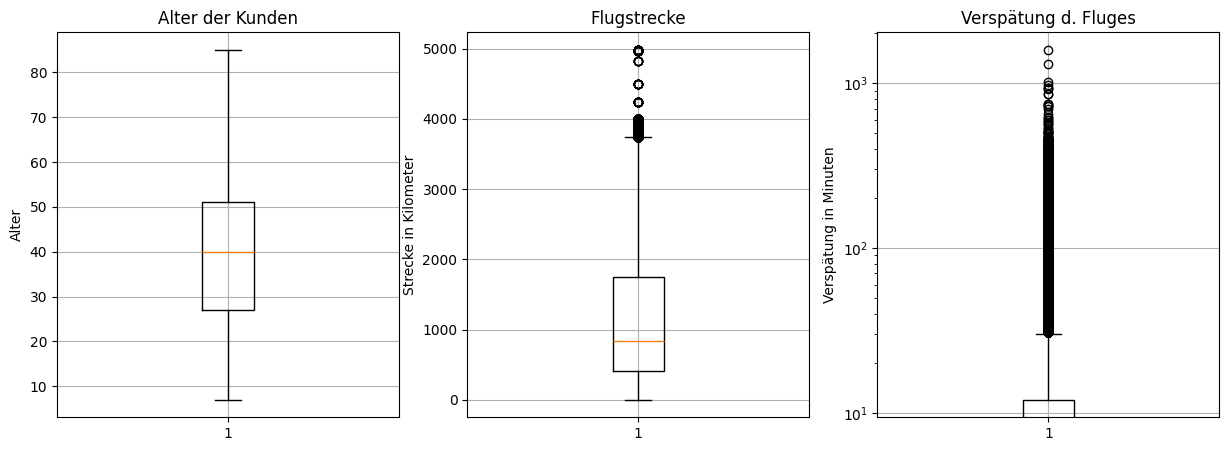

In [18]:
fig, ax = plt.subplots(1,3, figsize = (15,5))

ax[0].set_title("Alter der Kunden")
ax[0].set_ylabel("Alter")
ax[0].boxplot(df['Age'])
ax[0].grid()

ax[1].set_title("Flugstrecke")
ax[1].set_ylabel("Strecke in Kilometer")
ax[1].boxplot(df['Flight_Distance'])
ax[1].grid()

ax[2].set_title("Verspätung d. Fluges")
ax[2].set_ylabel("Verspätung in Minuten")
ax[2].set_yscale("log")
ax[2].boxplot(df['Departure_Delay_in_Minutes'])
ax[2].grid()

##### Outliers in "Verspätung d. Fluges" are no data errors -> might show massive delays & could be interesting for later analysis

### Scatter-Plot: Flugstrecke & Verspätung

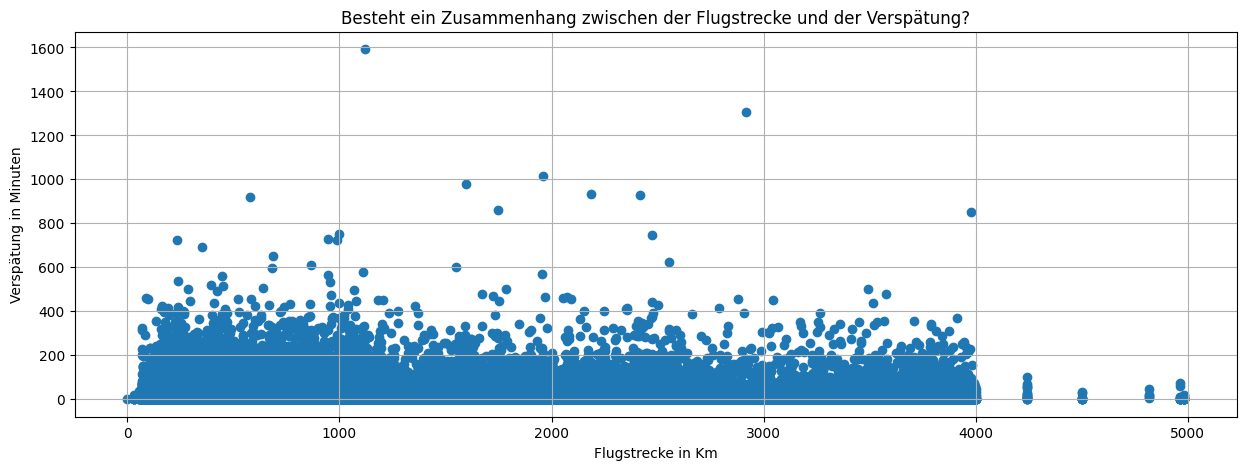

In [19]:
fig, ax = plt.subplots(1,1, figsize =(15,5))

ax.scatter(df['Flight_Distance'], df['Departure_Delay_in_Minutes'])
ax.set_title("Besteht ein Zusammenhang zwischen der Flugstrecke und der Verspätung?")
ax.set_ylabel("Verspätung in Minuten")
ax.set_xlabel("Flugstrecke in Km")
ax.grid()

### Gives no insights or extra value, will not be used in the presentation

***

>### 2. Data Exploration <a name="data_exploration">

#### correlation between class and satisfaction

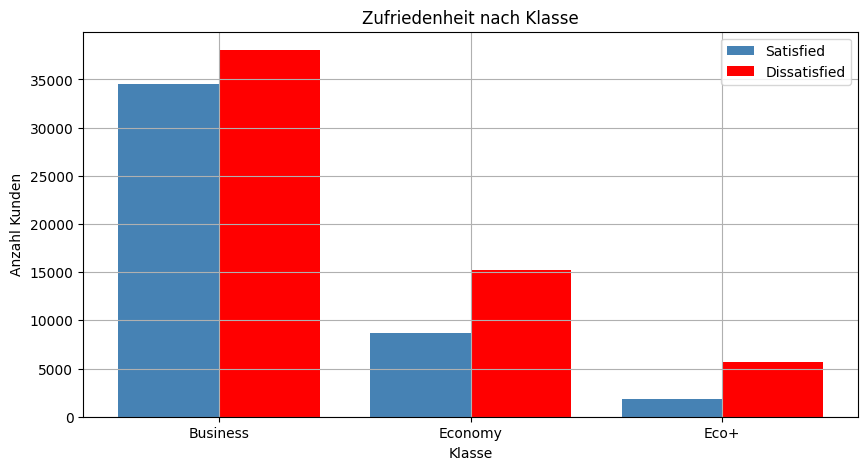

In [20]:
fig, ax = plt.subplots(figsize=(10, 5))

satisfied = df[df['satisfaction'] == 'satisfied']['Class'].value_counts()
dissatisfied = df[df['satisfaction'] == 'neutral or dissatisfied']['Class'].value_counts()

ax.bar(range(len(satisfied)), satisfied.values, width=0.4, color='steelblue', label='Satisfied')
ax.bar([i + 0.4 for i in range(len(satisfied))], dissatisfied.values, width=0.4, color='red', label='Dissatisfied')

ax.set_xticks([i + 0.2 for i in range(len(satisfied))])
ax.set_xticklabels(satisfied.index)
ax.set_title("Zufriedenheit nach Klasse")
ax.set_xlabel("Klasse")
ax.set_ylabel("Anzahl Kunden")
ax.legend()
ax.grid()
plt.show()


#### shows in ever yclass a relative impact on satisfaction, in total still dissatisfaction overweighs

### Visualizing satisfaction by reason of travel

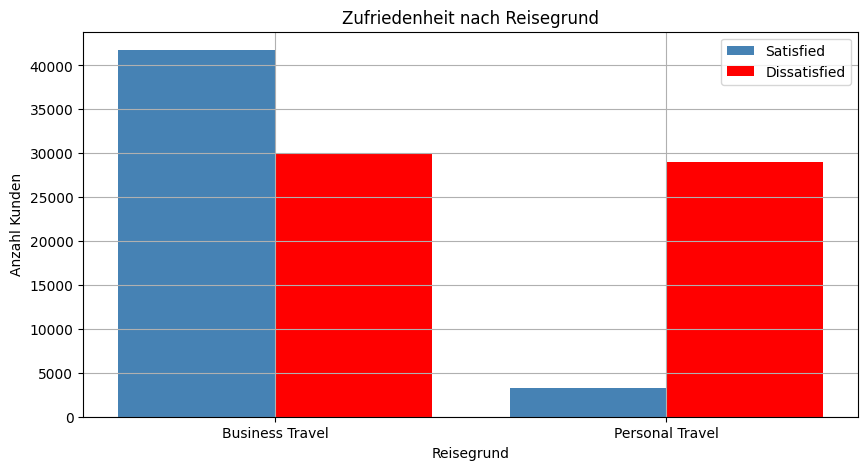

In [21]:
fig, ax = plt.subplots(figsize=(10, 5))

satisfied = df[df['satisfaction'] == 'satisfied']['Type_of_Travel'].value_counts()
dissatisfied = df[df['satisfaction'] == 'neutral or dissatisfied']['Type_of_Travel'].value_counts()

ax.bar(range(len(satisfied)), satisfied.values, width=0.4, color='steelblue', label='Satisfied')
ax.bar([i + 0.4 for i in range(len(satisfied))], dissatisfied.values, width=0.4, color='red', label='Dissatisfied')

ax.set_xticks([i + 0.2 for i in range(len(satisfied))])
ax.set_xticklabels(satisfied.index)
ax.set_title('Zufriedenheit nach Reisegrund')
ax.set_xlabel('Reisegrund')
ax.set_ylabel('Anzahl Kunden')
ax.legend()
ax.grid()
plt.show()


#### Customers that are traveling private are mostly dissatisfied, majority of travellers on Business Travel are satisfied
#### might be a good feature for later prediction

### Correlation between Customer_Type and satisfaction 

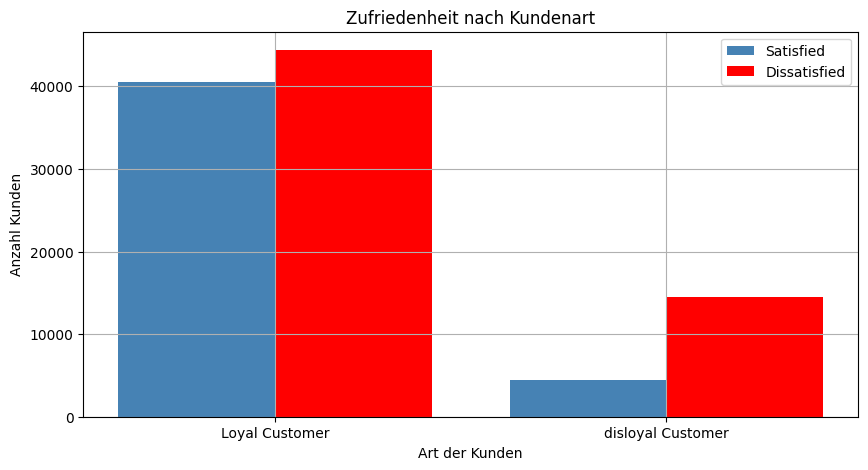

In [22]:
fig, ax = plt.subplots(figsize=(10, 5))

satisfied = df[df['satisfaction'] == 'satisfied']['Customer_Type'].value_counts()
dissatisfied = df[df['satisfaction'] == 'neutral or dissatisfied']['Customer_Type'].value_counts()

ax.bar(range(len(satisfied)), satisfied.values, width=0.4, color='steelblue', label='Satisfied')
ax.bar([i + 0.4 for i in range(len(satisfied))], dissatisfied.values, width=0.4, color='red', label='Dissatisfied')

ax.set_xticks([i + 0.2 for i in range(len(satisfied))])
ax.set_xticklabels(satisfied.index)
ax.set_title('Zufriedenheit nach Kundenart')
ax.set_xlabel('Art der Kunden')
ax.set_ylabel('Anzahl Kunden')
ax.legend()
ax.grid()
plt.show()


#### disloyal Customers are usually more dissatisfied, in both groups the majority is dissatisfied

### Age and satisfaction

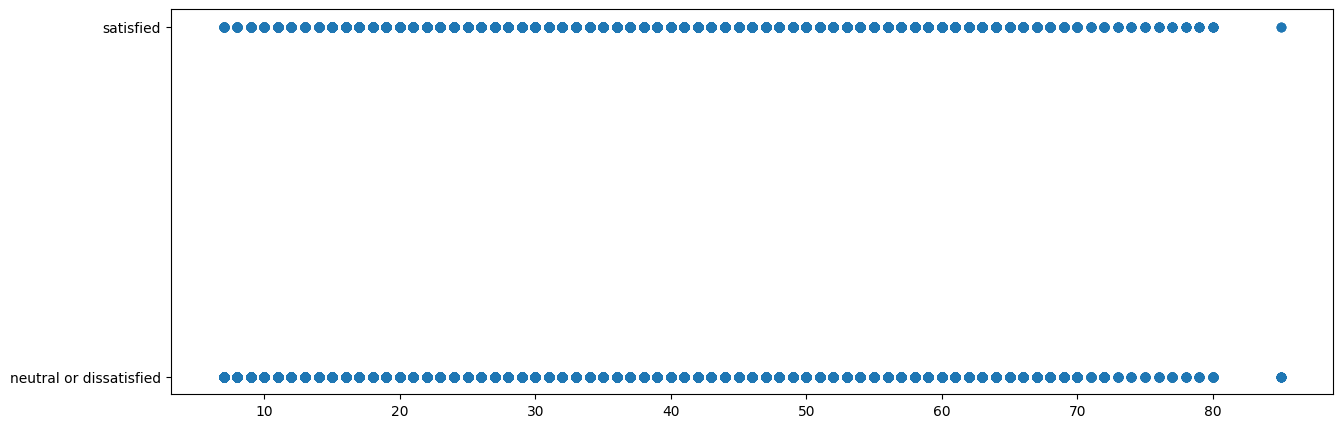

In [23]:
fig, ax = plt.subplots(1,1, figsize=(15,5))
ax.scatter(df['Age'], df['satisfaction'])

### useless, wont be used in presentation 

/var/folders/g4/s4dtm14s7jl3vfxm0ctdk6bc0000gn/T/ipykernel_73760/2242747897.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([satisfied_age, dissatisfied_age],


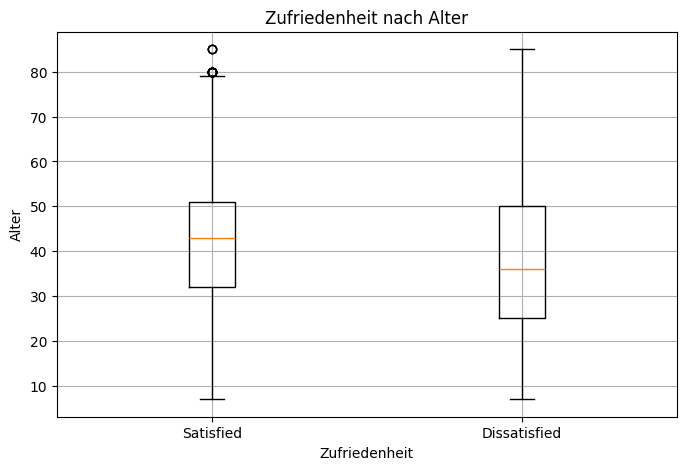

In [24]:
fig, ax = plt.subplots(figsize=(8, 5))

satisfied_age = df[df['satisfaction'] == 'satisfied']['Age']
dissatisfied_age = df[df['satisfaction'] == 'neutral or dissatisfied']['Age']

ax.boxplot([satisfied_age, dissatisfied_age], 
           labels=['Satisfied', 'Dissatisfied'])

ax.set_title('Zufriedenheit nach Alter')
ax.set_xlabel('Zufriedenheit')
ax.set_ylabel('Alter')
ax.grid()
plt.show()


#### dissatisfied customers are on average 35 years old, 10 years younger than satisfied customers with an average of 45 years
#### Agegroup of disatisfied customers is bigger
#### could be an interesting feature for prediction, will be checked later in a confusion matrix

### Delay & satisfaction

/var/folders/g4/s4dtm14s7jl3vfxm0ctdk6bc0000gn/T/ipykernel_73760/2051729772.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([satisfied_age, dissatisfied_age],


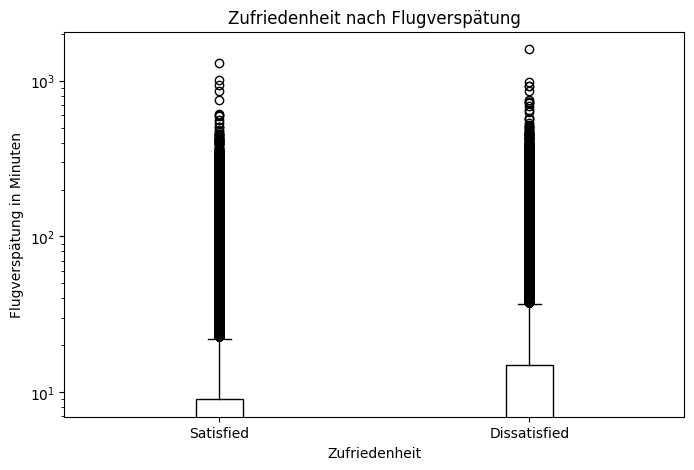

In [25]:
fig, ax = plt.subplots(figsize=(8, 5))

satisfied_age = df[df['satisfaction'] == 'satisfied']['Departure_Delay_in_Minutes']
dissatisfied_age = df[df['satisfaction'] == 'neutral or dissatisfied']['Departure_Delay_in_Minutes']

ax.boxplot([satisfied_age, dissatisfied_age], 
           labels=['Satisfied', 'Dissatisfied'])
ax.set_yscale('log')


ax.set_title('Zufriedenheit nach Flugverspätung')
ax.set_xlabel('Zufriedenheit')
ax.set_ylabel('Flugverspätung in Minuten')

plt.show()


#### Flight delay shows no difference in satisfaction

### Heatmap

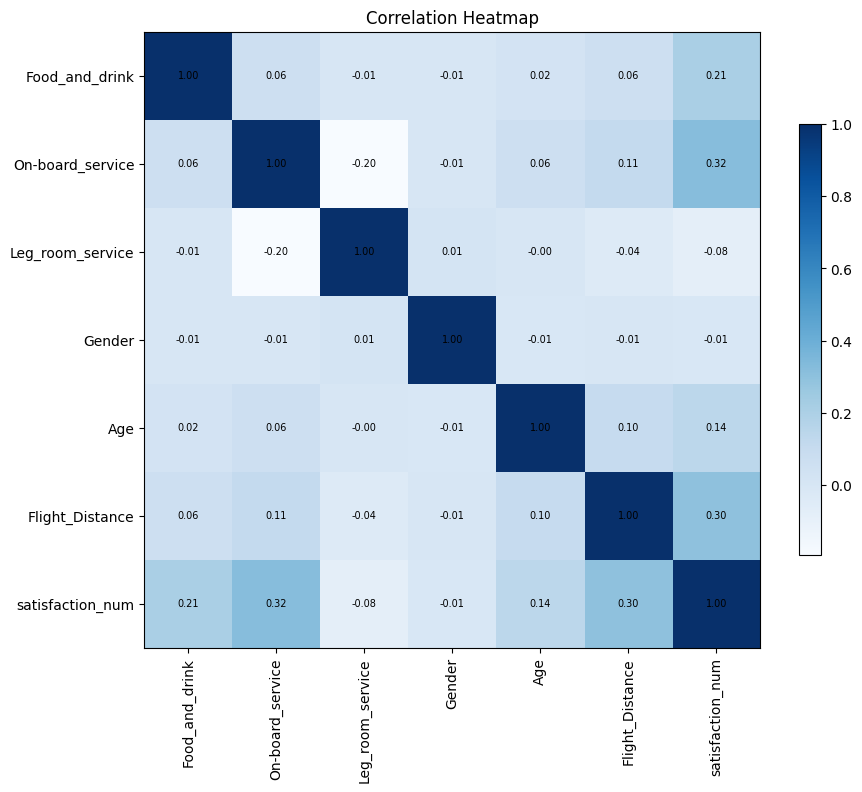

In [26]:
df['satisfaction_num'] = df['satisfaction'].map({
    'satisfied': 1,
    'neutral or dissatisfied': 0
})

df['Type_of_Travel'] = pd.factorize(df['Type_of_Travel'])[0]
df['Customer_Type'] = pd.factorize(df['Customer_Type'])[0]
df['Leg_room_service'] = pd.factorize(df['Leg_room_service'])[0]
df['Class'] = pd.factorize(df['Class'])[0]
df['Gender'] = pd.factorize(df['Gender'])[0]

relevant_cols = [
    'Food_and_drink', 'On-board_service', 'Leg_room_service','Gender', 'Age', 'Flight_Distance','satisfaction_num',
]

df_corr = df[relevant_cols].corr()

fig, ax = plt.subplots(figsize=(10,8))
img = ax.imshow(df_corr, cmap="Blues")
# Legende
fig.colorbar(img, shrink=0.7)

for i in range(df_corr.shape[0]):
    for j in range(df_corr.shape[1]):
        ax.text(j, i, f'{df_corr.iloc[i, j]:.2f}', ha="center", va="center", color="black", fontsize=7)
        
ax.set_xticks(range(len(df_corr.columns)), df_corr.columns, rotation=90)
ax.set_yticks(range(len(df_corr.columns)), df_corr.columns)
ax.set_title("Correlation Heatmap")

plt.show()


#### Gender, Departure_Delay_in_Minutes, Age & Leg_room_service have a low correlation, will be dropped in the next step

***

>### 3. Predictive Modelling <a name="predictive_modelling">

### Deleting irrelevant columns for the model

In [27]:
df = df.drop(columns=['Gender', 'satisfaction', 'Departure_Delay_in_Minutes', 'Leg_room_service', 'Age' ])




              precision    recall  f1-score   support

           0       0.81      0.82      0.81     11663
           1       0.77      0.75      0.76      9119

    accuracy                           0.79     20782
   macro avg       0.79      0.78      0.79     20782
weighted avg       0.79      0.79      0.79     20782



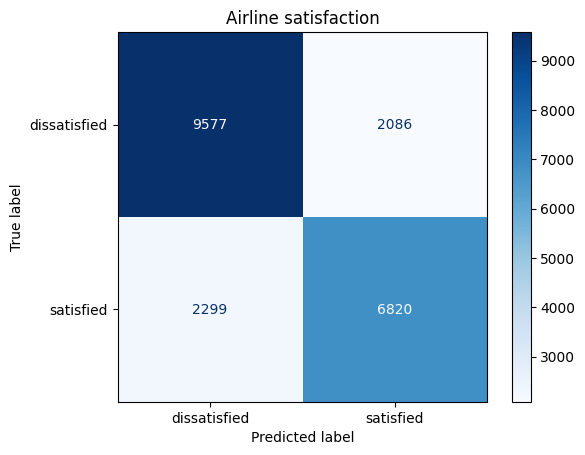

In [28]:




X = df.drop(columns=['satisfaction_num'])
y = df['satisfaction_num']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Modell Training
clf = RandomForestClassifier()
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred))

# Platzhalter für Confusion Matrix Visualisierung
cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['dissatisfied', 'satisfied'])
disp.plot(cmap='Blues', values_format ='d')
plt.title('Airline satisfaction')
plt.show()